## Exploratory Data Analysis (EDA) – Titanic Dataset

### SWYNEX Data Analyst Internship – Task 2

#### Project Overview
This project focuses on exploring the cleaned Titanic dataset using Python.

#### Objectives
- Understand the dataset structure.
- Calculate descriptive statistics.
- Analyze passenger survival patterns.
- Identify trends and anomalies.
- Create meaningful visualizations.
- Extract useful insights from the data.

### 1. Importing Required Libraries

We will use Pandas and NumPy for data analysis and Matplotlib and Seaborn for data visualization.

In [4]:
%pip install matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)


Pandas: 2.3.3
NumPy: 2.2.6
Matplotlib: 3.10.9
Seaborn: 0.13.2


In [29]:
df = pd.read_csv("../data/titanic_cleaned.csv")

print(df.shape)

df.head()


(891, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


In [31]:
# Check missing values in each column

df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [32]:
# Check duplicate records

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [33]:
# Generate descriptive statistics

df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.112424,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.304424,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,21.500000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,26.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,36.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [34]:
# Count passengers by survival status

survival_counts = df["Survived"].value_counts()

print("Survival Counts:")
print(survival_counts)

print("\n0 = Did not survive")
print("1 = Survived")

Survival Counts:
Survived
0    549
1    342
Name: count, dtype: int64

0 = Did not survive
1 = Survived


In [35]:
# Calculate survival percentage

survival_percentage = df["Survived"].value_counts(normalize=True) * 100

print(survival_percentage.round(2))

Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


## 3. Survival Distribution

This section examines the number of passengers who survived and did not survive the Titanic disaster.

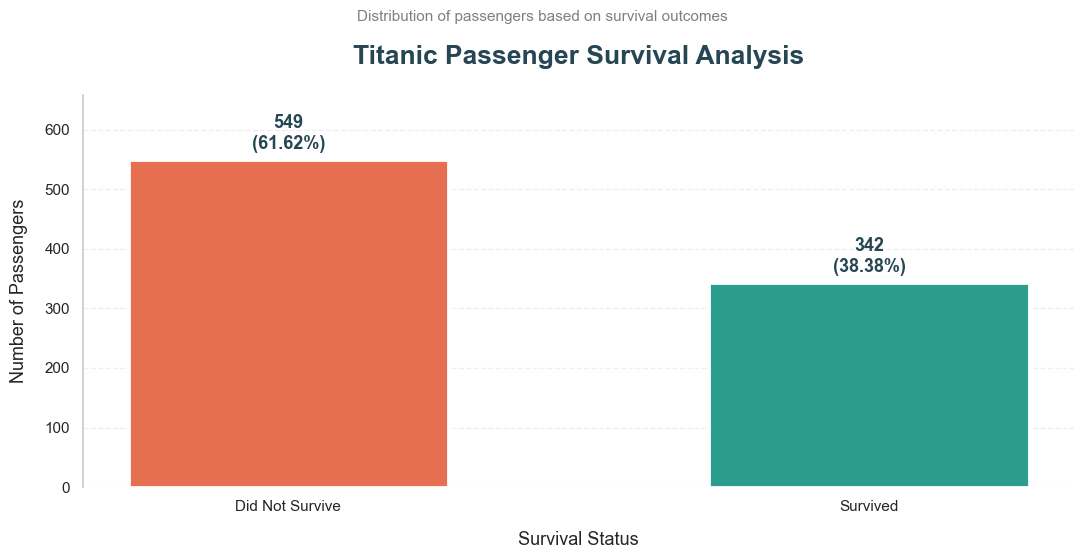

In [36]:

# ==========================================
# TITANIC PASSENGER SURVIVAL DISTRIBUTION
# ==========================================

# Set professional visualization style
sns.set_theme(style="whitegrid", context="notebook")

# Calculate survival counts and percentages
survival_counts = df["Survived"].value_counts().sort_index()
total_passengers = len(df)
survival_percentages = (survival_counts / total_passengers) * 100

# Create figure
fig, ax = plt.subplots(figsize=(11, 6))

# Create bar chart
bars = ax.bar(
    ["Did Not Survive", "Survived"],
    survival_counts.values,
    color=["#E76F51", "#2A9D8F"],
    width=0.55,
    edgecolor="white",
    linewidth=2
)

# Add count and percentage labels
for bar, count, percentage in zip(
    bars,
    survival_counts.values,
    survival_percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 12,
        f"{count}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        color="#264653"
    )

# Add title and labels
ax.set_title(
    "Titanic Passenger Survival Analysis",
    fontsize=19,
    fontweight="bold",
    color="#264653",
    pad=22
)

ax.set_xlabel("Survival Status", fontsize=13, labelpad=12)
ax.set_ylabel("Number of Passengers", fontsize=13, labelpad=12)

# Improve chart appearance
ax.set_ylim(0, max(survival_counts.values) * 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)

sns.despine(left=False, bottom=True)

# Add subtitle
fig.text(
    0.5, 0.91,
    "Distribution of passengers based on survival outcomes",
    ha="center",
    fontsize=11,
    color="gray"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.savefig("../visuals/01_survival_analysis.png", dpi=300, bbox_inches="tight")
plt.show()


In [37]:
# Calculate survival counts by gender

gender_survival = df.groupby(["Sex", "Survived"]).size().unstack()

print("Survival Count by Gender:")
print(gender_survival)

Survival Count by Gender:
Survived    0    1
Sex               
female     81  233
male      468  109


In [38]:
# Calculate survival percentage by gender

gender_survival_rate = df.groupby("Sex")["Survived"].mean() * 100

print("Survival Rate by Gender:")
print(gender_survival_rate.round(2))

Survival Rate by Gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


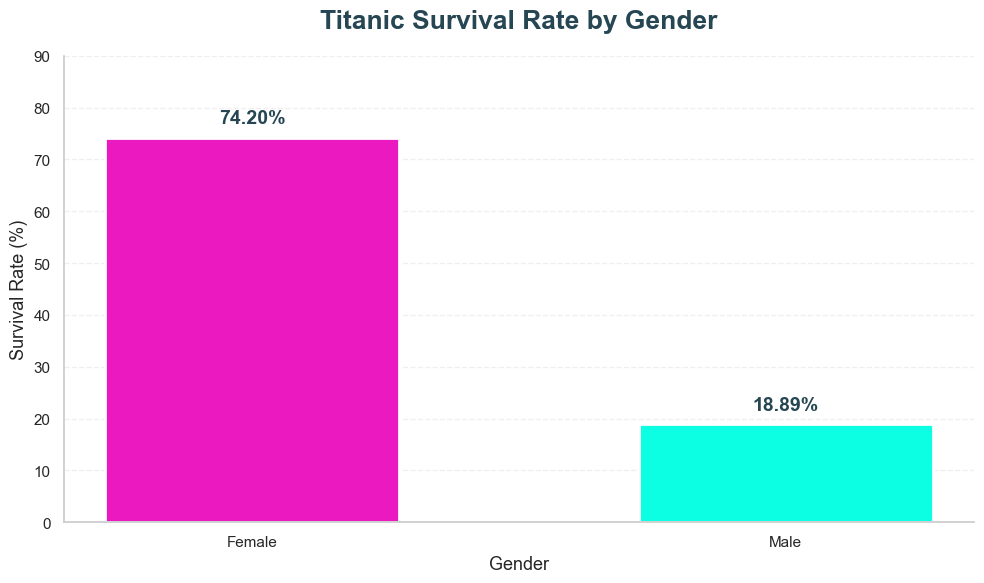

In [39]:

# ==========================================
# SURVIVAL RATE BY GENDER
# ==========================================

# Calculate survival rates
gender_rates = df.groupby("Sex")["Survived"].mean() * 100

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Create bar chart
bars = ax.bar(
    gender_rates.index.str.title(),
    gender_rates.values,
    color=["#EA1AC0", "#0DFFE3"],
    width=0.55,
    edgecolor="white",
    linewidth=2
)

# Add percentage labels
for bar, rate in zip(bars, gender_rates.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold",
        color="#264653"
    )

# Chart title and labels
ax.set_title(
    "Titanic Survival Rate by Gender",
    fontsize=19,
    fontweight="bold",
    color="#264653",
    pad=20
)

ax.set_xlabel("Gender", fontsize=13)
ax.set_ylabel("Survival Rate (%)", fontsize=13)

ax.set_ylim(0, 90)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)

sns.despine()

plt.tight_layout()
plt.savefig("../visuals/02_gender_survival.png", dpi=300, bbox_inches="tight")
plt.show()

In [40]:
# Calculate survival rate by passenger class

class_survival = df.groupby("Pclass")["Survived"].mean() * 100

print("Survival Rate by Passenger Class:")
print(class_survival.round(2))

Survival Rate by Passenger Class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


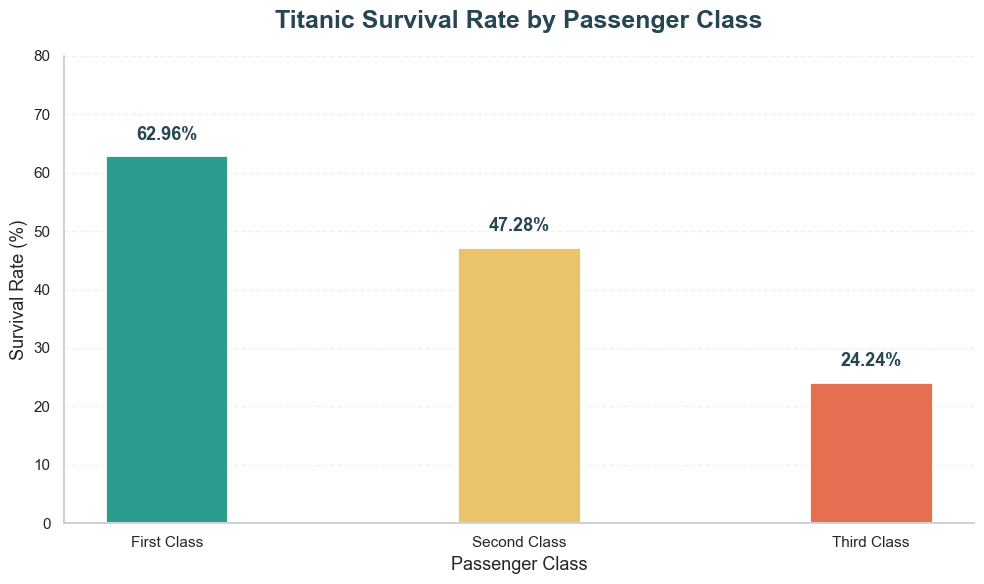

In [41]:

# ==========================================
# SURVIVAL RATE BY PASSENGER CLASS
# ==========================================

# Calculate survival rate
class_survival = df.groupby("Pclass")["Survived"].mean() * 100

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Create bar chart
bars = ax.bar(
    ["First Class", "Second Class", "Third Class"],
    class_survival.values,
    color=["#2A9D8F", "#E9C46A", "#E76F51"],
    width=0.35,
    edgecolor="white",
    linewidth=2
)

# Add percentage labels
for bar, rate in zip(bars, class_survival.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        color="#264653"
    )

# Add title and labels
ax.set_title(
    "Titanic Survival Rate by Passenger Class",
    fontsize=18,
    fontweight="bold",
    color="#264653",
    pad=20
)

ax.set_xlabel("Passenger Class", fontsize=13)
ax.set_ylabel("Survival Rate (%)", fontsize=13)

ax.set_ylim(0, 80)

# Improve appearance
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.savefig("../visuals/03_class_survival.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
# ==========================================
# SURVIVAL ANALYSIS BY AGE
# ==========================================

age_survival = df.groupby("Survived")["Age"].mean()

print("Average Age by Survival Status:")
print(age_survival.round(2))

print("\n0 = Did Not Survive")
print("1 = Survived")

Average Age by Survival Status:
Survived
0    29.74
1    28.11
Name: Age, dtype: float64

0 = Did Not Survive
1 = Survived


In [43]:
# ==========================================
# GROUP PASSENGERS BY AGE
# ==========================================

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

# Calculate survival rate by age group
age_group_survival = df.groupby(
    "AgeGroup", observed=False
)["Survived"].mean() * 100

print("Survival Rate by Age Group:")
print(age_group_survival.round(2))

Survival Rate by Age Group:
AgeGroup
Child          57.97
Teenager       42.86
Young Adult    35.80
Adult          38.43
Senior         22.73
Name: Survived, dtype: float64


In [44]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

print(df["AgeGroup"].value_counts().sort_index())

AgeGroup
Child           69
Teenager        70
Young Adult    514
Adult          216
Senior          22
Name: count, dtype: int64


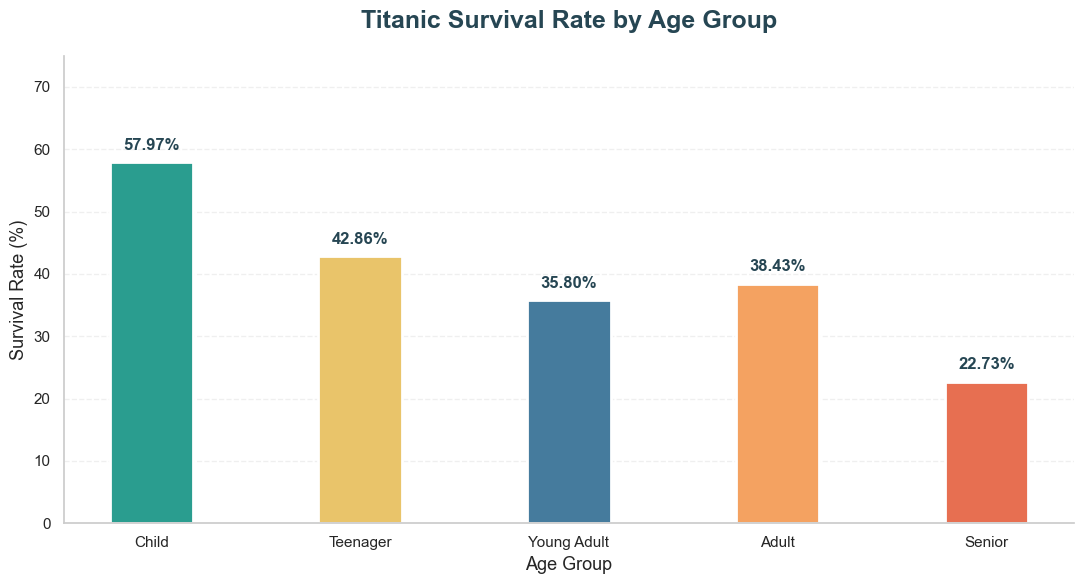

In [45]:

# ==========================================
# SURVIVAL RATE BY AGE GROUP
# ==========================================

# Calculate survival rate by age group
age_group_survival = (
    df.groupby("AgeGroup", observed=False)["Survived"].mean() * 100
)

# Create figure
fig, ax = plt.subplots(figsize=(11, 6))

# Define professional colours
colors = ["#2A9D8F", "#E9C46A", "#457B9D", "#F4A261", "#E76F51"]

# Create bar chart
bars = ax.bar(
    age_group_survival.index.astype(str),
    age_group_survival.values,
    color=colors,
    width=0.40,
    edgecolor="white",
    linewidth=2
)

# Add percentage labels
for bar, rate in zip(bars, age_group_survival.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        color="#264653"
    )

# Add chart title and labels
ax.set_title(
    "Titanic Survival Rate by Age Group",
    fontsize=18,
    fontweight="bold",
    color="#264653",
    pad=20
)

ax.set_xlabel("Age Group", fontsize=13)
ax.set_ylabel("Survival Rate (%)", fontsize=13)

ax.set_ylim(0, 75)

# Improve appearance
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.savefig("../visuals/04_age_survival.png", dpi=300, bbox_inches="tight")
plt.show()


In [46]:
# ==========================================
# FARE DISTRIBUTION ANALYSIS
# ==========================================

print("Fare Statistics:")
print(df["Fare"].describe().round(2))


Fare Statistics:
count    891.00
mean      32.20
std       49.69
min        0.00
25%        7.91
50%       14.45
75%       31.00
max      512.33
Name: Fare, dtype: float64


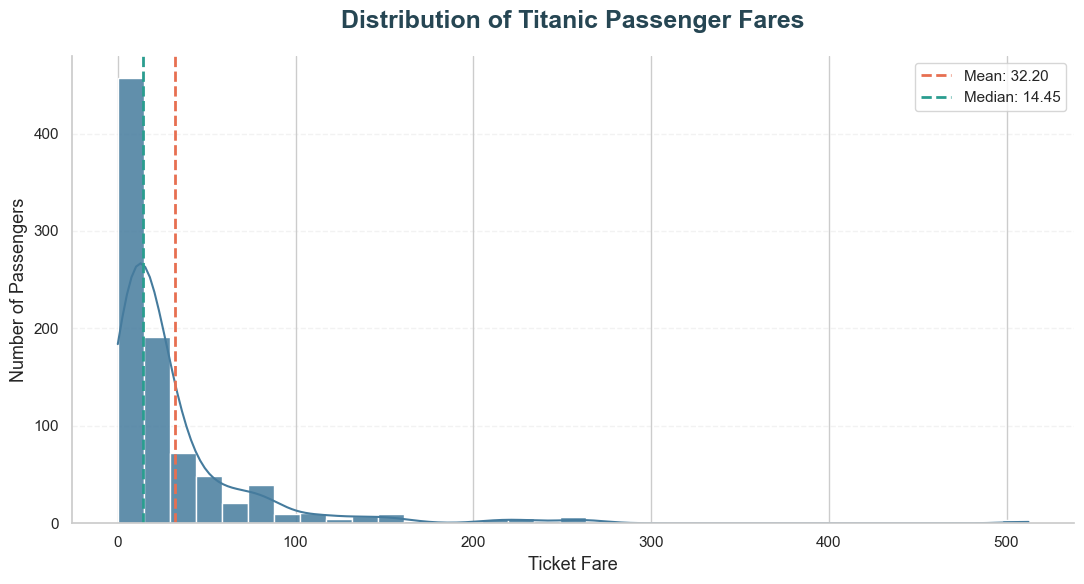

In [47]:

# ==========================================
# TITANIC FARE DISTRIBUTION
# ==========================================

fig, ax = plt.subplots(figsize=(11, 6))

# Create histogram
sns.histplot(
    data=df,
    x="Fare",
    bins=35,
    kde=True,
    color="#457B9D",
    edgecolor="white",
    alpha=0.85,
    ax=ax
)

# Add mean and median reference lines
ax.axvline(
    df["Fare"].mean(),
    color="#E76F51",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {df['Fare'].mean():.2f}"
)

ax.axvline(
    df["Fare"].median(),
    color="#2A9D8F",
    linestyle="--",
    linewidth=2,
    label=f"Median: {df['Fare'].median():.2f}"
)

# Add title and labels
ax.set_title(
    "Distribution of Titanic Passenger Fares",
    fontsize=18,
    fontweight="bold",
    color="#264653",
    pad=20
)

ax.set_xlabel("Ticket Fare", fontsize=13)
ax.set_ylabel("Number of Passengers", fontsize=13)

ax.legend(frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.25)

sns.despine()
plt.tight_layout()
plt.savefig("../visuals/05_fare_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


### Fare Outlier Detection Using the IQR Method

The Interquartile Range (IQR) method is used to identify unusually high or low ticket fares in the dataset.

In [48]:

# ==========================================
# FARE OUTLIER DETECTION USING IQR
# ==========================================

# Calculate first and third quartiles
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

# Calculate Interquartile Range
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify outliers
fare_outliers = df[
    (df["Fare"] < lower_limit) |
    (df["Fare"] > upper_limit)
]

# Display results
print("First Quartile (Q1):", round(Q1, 2))
print("Third Quartile (Q3):", round(Q3, 2))
print("Interquartile Range (IQR):", round(IQR, 2))
print("Lower Limit:", round(lower_limit, 2))
print("Upper Limit:", round(upper_limit, 2))
print("Number of Fare Outliers:", len(fare_outliers))


First Quartile (Q1): 7.91
Third Quartile (Q3): 31.0
Interquartile Range (IQR): 23.09
Lower Limit: -26.72
Upper Limit: 65.63
Number of Fare Outliers: 116


### Fare Distribution and Outlier Visualization

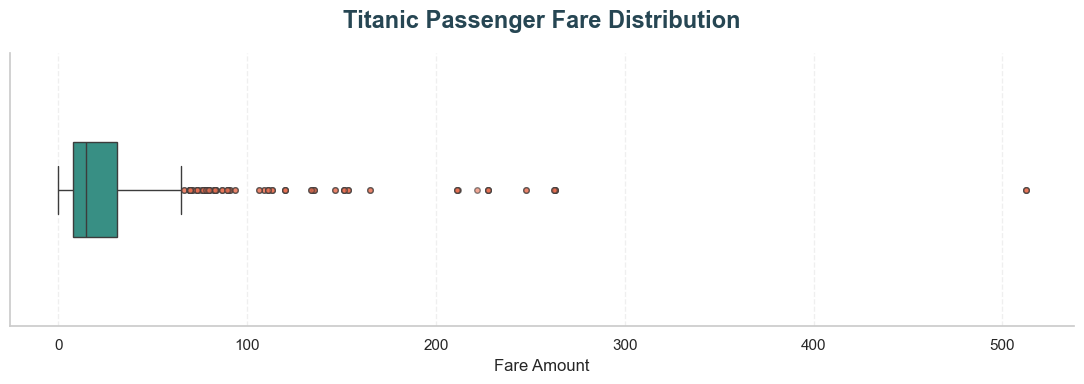

In [49]:
plt.figure(figsize=(11, 4))

sns.boxplot(
    x=df["Fare"],
    color="#2A9D8F",
    width=0.35,
    flierprops={
        "marker": "o",
        "markerfacecolor": "#E76F51",
        "markersize": 4,
        "alpha": 0.6
    }
)

plt.title(
    "Titanic Passenger Fare Distribution",
    fontsize=17,
    fontweight="bold",
    color="#264653",
    pad=18
)

plt.xlabel("Fare Amount", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.savefig("../visuals/06_fare_outliers.png", dpi=300, bbox_inches="tight")
plt.show()

## Family Size and Survival Analysis

In [50]:
# Calculate family size
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

# Calculate survival rate by family size
family_survival = (
    df.groupby("FamilySize")["Survived"]
    .agg(["count", "mean"])
)

family_survival["SurvivalRate"] = family_survival["mean"] * 100

family_survival = family_survival.rename(
    columns={"count": "PassengerCount"}
)

print(family_survival[["PassengerCount", "SurvivalRate"]].round(2))

            PassengerCount  SurvivalRate
FamilySize                              
1                      537         30.35
2                      161         55.28
3                      102         57.84
4                       29         72.41
5                       15         20.00
6                       22         13.64
7                       12         33.33
8                        6          0.00
11                       7          0.00


### Survival Rate by Family Size

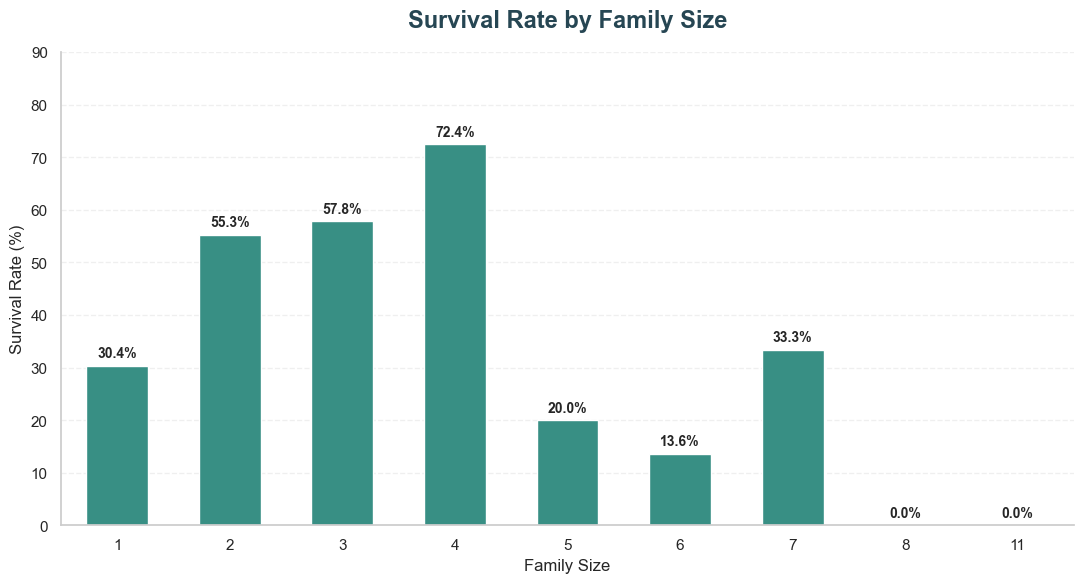

In [51]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=family_survival.index,
    y=family_survival["SurvivalRate"],
    color="#2A9D8F",
    width=0.55
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=4,
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Survival Rate by Family Size",
    fontsize=17,
    fontweight="bold",
    color="#264653",
    pad=18
)

plt.xlabel("Family Size", fontsize=12)
plt.ylabel("Survival Rate (%)", fontsize=12)
plt.ylim(0, 90)
plt.grid(axis="y", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.savefig("../visuals/07_family_size.png", dpi=300, bbox_inches="tight")
plt.show()

## Survival Analysis by Embarkation Port

In [52]:
# Calculate passenger count and survival rate by port
embarked_analysis = (
    df.groupby("Embarked")["Survived"]
    .agg(["count", "mean"])
)

embarked_analysis = embarked_analysis.rename(
    columns={
        "count": "PassengerCount",
        "mean": "SurvivalRate"
    }
)

embarked_analysis["SurvivalRate"] *= 100

print(embarked_analysis.round(2))

          PassengerCount  SurvivalRate
Embarked                              
C                    168         55.36
Q                     77         38.96
S                    646         33.90


## Survival Rate by Embarkation Port

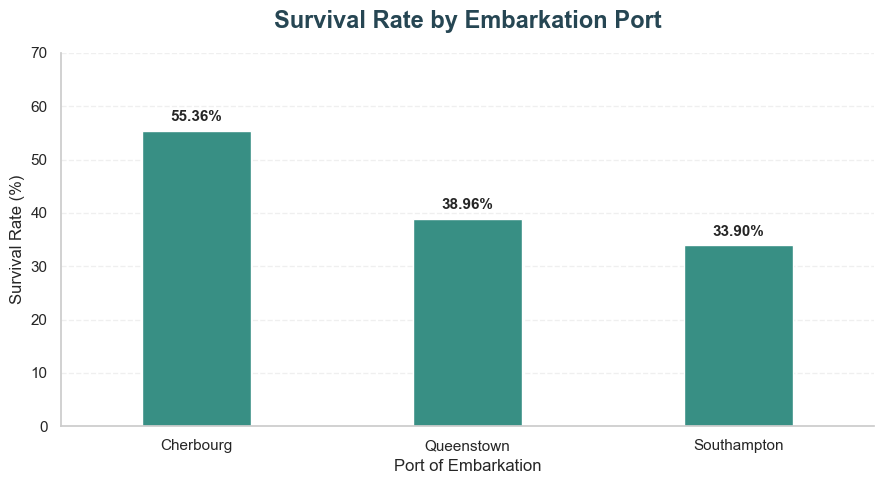

In [53]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=embarked_analysis.index,
    y=embarked_analysis["SurvivalRate"],
    color="#2A9D8F",
    width=0.4
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=5,
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Survival Rate by Embarkation Port",
    fontsize=17,
    fontweight="bold",
    color="#264653",
    pad=18
)

plt.xlabel("Port of Embarkation", fontsize=12)
plt.ylabel("Survival Rate (%)", fontsize=12)
plt.ylim(0, 70)
plt.grid(axis="y", linestyle="--", alpha=0.3)
sns.despine()
plt.xticks(
    ticks=[0, 1, 2],
    labels=["Cherbourg", "Queenstown", "Southampton"]
)
plt.tight_layout()
plt.savefig("../visuals/08_embarkation_port.png", dpi=300, bbox_inches="tight")
plt.show()

## Correlation Analysis

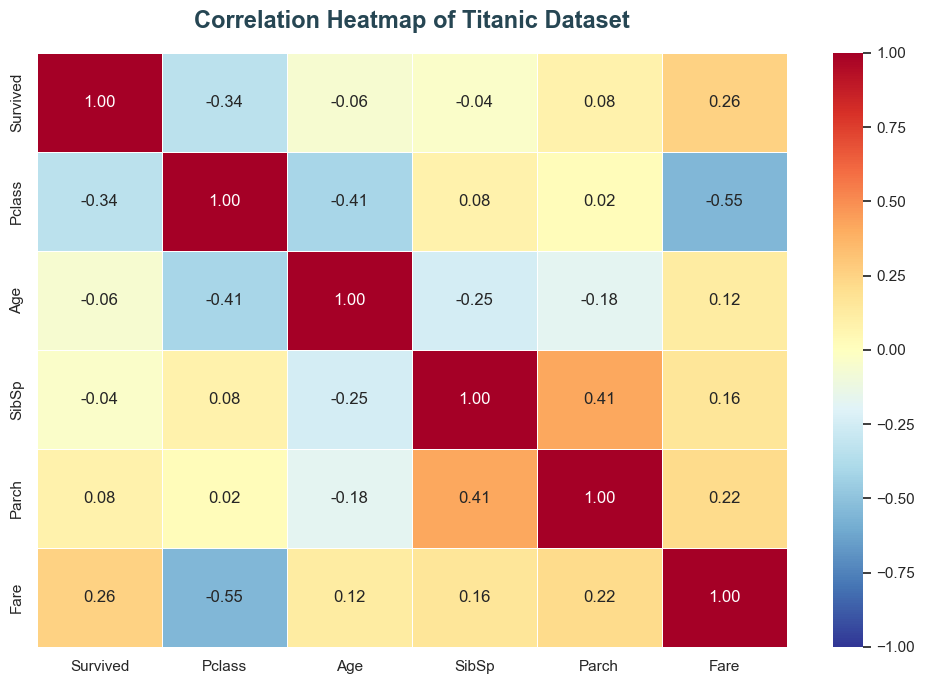

In [54]:
# Select numerical columns
numeric_df = df[
    ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
]

# Calculate correlation
correlation = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="RdYlBu_r",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlation Heatmap of Titanic Dataset",
    fontsize=17,
    fontweight="bold",
    color="#264653",
    pad=18
)

plt.tight_layout()
plt.savefig("../visuals/09_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## Combined Gender and Passenger Class Analysis

In [55]:
# Survival rate by gender and passenger class
gender_class_analysis = (
    df.groupby(["Sex", "Pclass"])["Survived"]
    .agg(["count", "mean"])
)

gender_class_analysis = gender_class_analysis.rename(
    columns={
        "count": "PassengerCount",
        "mean": "SurvivalRate"
    }
)

gender_class_analysis["SurvivalRate"] *= 100

print(gender_class_analysis.round(2))

               PassengerCount  SurvivalRate
Sex    Pclass                              
female 1                   94         96.81
       2                   76         92.11
       3                  144         50.00
male   1                  122         36.89
       2                  108         15.74
       3                  347         13.54


## Survival Rate by Gender and Passenger Class

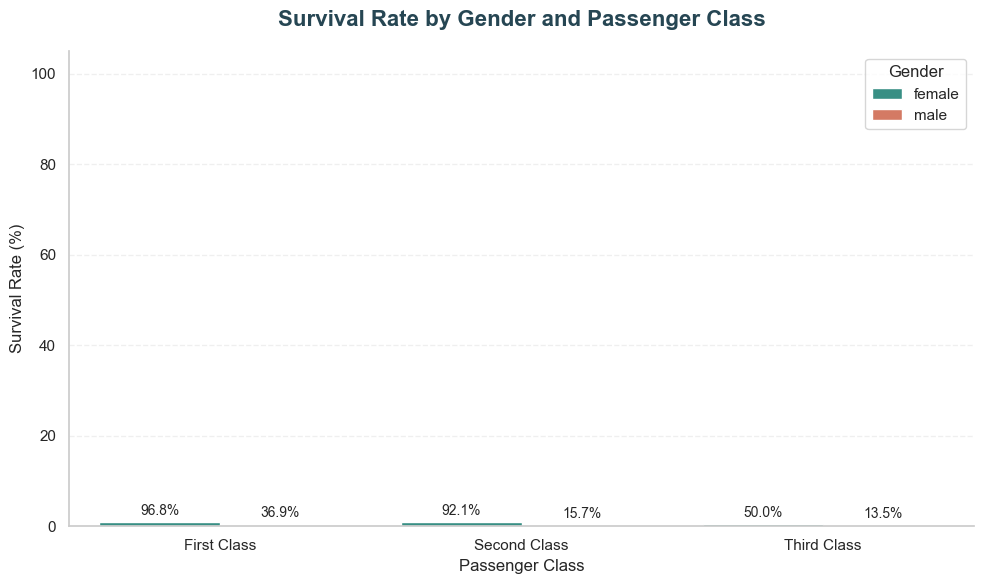

In [56]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=df,
    x="Pclass",
    y="Survived",
    hue="Sex",
    palette={"female": "#2A9D8F", "male": "#E76F51"},
    errorbar=None
)

# Convert survival proportions into percentages
for container in ax.containers:
    labels = [
        f"{bar.get_height() * 100:.1f}%"
        if bar.get_height() > 0 else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, padding=3, fontsize=10)

plt.title(
    "Survival Rate by Gender and Passenger Class",
    fontsize=16,
    fontweight="bold",
    color="#264653",
    pad=18
)

plt.xlabel("Passenger Class", fontsize=12)
plt.ylabel("Survival Rate (%)", fontsize=12)
plt.xticks([0, 1, 2], ["First Class", "Second Class", "Third Class"])
plt.ylim(0, 105)
plt.yticks(range(0, 101, 20))
plt.legend(title="Gender")
plt.grid(axis="y", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.savefig("../visuals/10_gender_class.png", dpi=300, bbox_inches="tight")
plt.show()

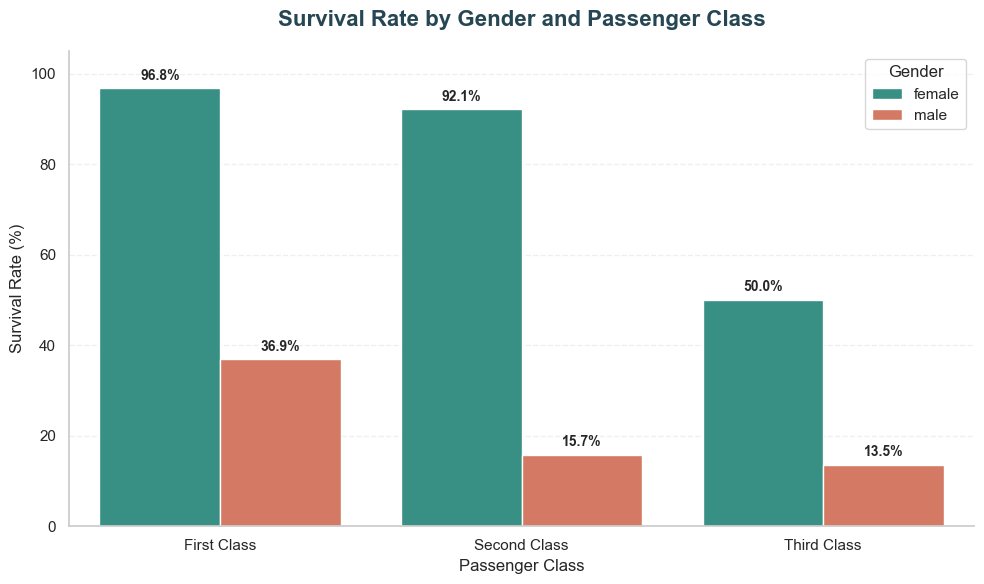

In [57]:
# Create a percentage column
df["SurvivalPercent"] = df["Survived"] * 100

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=df,
    x="Pclass",
    y="SurvivalPercent",
    hue="Sex",
    palette={"female": "#2A9D8F", "male": "#E76F51"},
    errorbar=None
)

for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%"
        for bar in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        padding=4,
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Survival Rate by Gender and Passenger Class",
    fontsize=16,
    fontweight="bold",
    color="#264653",
    pad=18
)

plt.xlabel("Passenger Class", fontsize=12)
plt.ylabel("Survival Rate (%)", fontsize=12)
plt.xticks([0, 1, 2], ["First Class", "Second Class", "Third Class"])
plt.ylim(0, 105)
plt.yticks(range(0, 101, 20))
plt.legend(title="Gender")
plt.grid(axis="y", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

## Key Insights from Exploratory Data Analysis

### Key Insights

1. **Overall Survival:** Out of 891 passengers, 342 survived (38.38%), while 549 did not survive (61.62%).

2. **Gender and Survival:** Female passengers had a survival rate of 74.20%, compared with 18.89% for male passengers.

3. **Passenger Class:** First-class passengers had the highest survival rate (62.96%), followed by second class (47.28%) and third class (24.24%).

4. **Age Groups:** Children had the highest survival rate (57.97%) among the age groups analysed, while senior passengers had the lowest (22.73%).

5. **Fare Analysis:** The average fare was 32.20, and 116 passengers were identified as potential fare outliers using the IQR method.

6. **Family Size:** Passengers travelling in families of 2–4 members generally had higher survival rates than passengers travelling alone.

7. **Embarkation Port:** Passengers boarding at Cherbourg had the highest survival rate (55.36%), compared with Queenstown (38.96%) and Southampton (33.90%).

8. **Gender and Passenger Class Together:** First-class female passengers had the highest survival rate (96.81%), while third-class male passengers had the lowest (13.54%).

## Conclusion

The Exploratory Data Analysis of the Titanic dataset helped identify important patterns and relationships among passenger characteristics and survival outcomes.

The analysis showed that gender, passenger class, age group, family size, fare and embarkation port were associated with differences in survival rates.

Female passengers and first-class passengers generally had higher survival rates. Passengers travelling with small families also showed better survival outcomes than those travelling alone.

The analysis also identified potential fare outliers using the Interquartile Range (IQR) method and examined numerical relationships using a correlation heatmap.

Overall, this project provided practical experience in data analysis, statistical calculations, data visualization and extracting meaningful insights using Python, Pandas, NumPy, Matplotlib and Seaborn.